# 随机森林

### 问题

决策树最大的毛病是方差大:训练数据换一批,树的结构可能完全不一样,测试集上的分数能差好几个点。

随机森林的思路很直接:多训几棵树,让它们投票。但光用同一份数据训出来的树长得都差不多,投票也没意义,所以要人为制造差异:

1. **bagging**:每棵树用有放回抽样得到的一份新数据训练,大概三分之一的样本抽不到;
2. **随机特征**:每次分裂时只从随机选出的几个特征里挑最好的那个,默认 `max_features="sqrt"`,30 个特征时每次只看 5 个。

第一点让每棵树看到的数据不同,第二点让它们连考虑的特征都不同,树之间越不相关,平均之后方差降得越多。

## 1. 数据

还是用决策树那里的月牙形数据,600 个点,噪声 0.35。树在这个数据上很容易把噪声记住。

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

# 本机 numpy 2.0 会对 matmul 误报浮点警告,结果是对的
warnings.filterwarnings("ignore", message=".*in matmul")

# 中文和负号
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=600, noise=0.35, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

print(X_train.shape, X_test.shape)

(420, 2) (180, 2)


## 2. 先看看单棵树有多不稳

模拟 bagging 的做法:从训练集里有放回地抽同样多的样本,训 20 棵树,看它们在同一份测试集上的分数。

In [2]:
from sklearn.tree import DecisionTreeClassifier

rng = np.random.default_rng(0)
scores = []

for i in range(20):
    idx = rng.integers(0, len(X_train), len(X_train))
    t = DecisionTreeClassifier(random_state=i).fit(X_train[idx], y_train[idx])
    scores.append(t.score(X_test, y_test))

print("平均", round(np.mean(scores), 3), "标准差", round(np.std(scores), 3))
print("最低", round(min(scores), 3), "最高", round(max(scores), 3))

平均 0.816 标准差 0.022
最低 0.778 最高 0.856


20 棵树的测试分数从 0.778 到 0.856,标准差 0.022。也就是说随便训一棵树,你都不知道自己拿到的是哪个水平。

要是把这 20 棵树的预测平均一下,方差就能压下去。

## 3. 训练一片森林

`RandomForestClassifier` 就是上面两件事一起做。为了公平比较,用 5 折交叉验证算平均分。

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

tree_cv = cross_val_score(DecisionTreeClassifier(random_state=0), X, y, cv=5).mean()
rf_cv = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=0), X, y, cv=5).mean()

print("单树 CV:", round(tree_cv, 4))
print("森林 CV:", round(rf_cv, 4))

单树 CV: 0.8333
森林 CV: 0.8717


单树 0.833,森林 0.872。提升不算巨大,因为这份数据的贝叶斯错误率本身就高,噪声点谁都分不对。森林赚的是稳定性,不是把天花板抬高。

## 4. 树的数量

森林里到底要几棵树?把 n_estimators 从小到大扫一遍。

In [4]:
ns = [1, 2, 5, 10, 20, 50, 100, 200]
cv_scores = []

for n in ns:
    s = cross_val_score(RandomForestClassifier(n_estimators=n, random_state=0), X, y, cv=5).mean()
    cv_scores.append(s)
    print(f"n={n:<4} cv={s:.4f}")

n=1    cv=0.8383
n=2    cv=0.8333
n=5    cv=0.8517
n=10   cv=0.8567
n=20   cv=0.8583


n=50   cv=0.8650


n=100  cv=0.8717


n=200  cv=0.8733


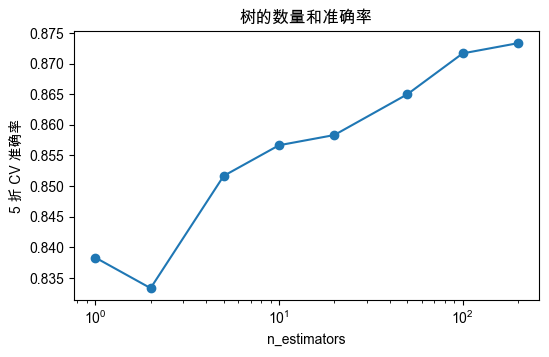

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ns, cv_scores, marker="o")
ax.set_xscale("log")
ax.set_xlabel("n_estimators")
ax.set_ylabel("5 折 CV 准确率")
ax.set_title("树的数量和准确率")
plt.show()

一开始涨得很快,50 棵以后基本平了,100 到 200 只差 0.001。再往上加,准确率不太会变,但训练和预测时间线性增长,所以一般给 100 到 300 就够。

n=1 的森林其实还是一棵树,只是用了 bootstrap 样本;n=2 反而掉了 0.005,树太少的时候平均没有意义,波动还在。

## 5. 决策边界

单棵树和 200 棵树的边界放在一起看,区别很明显。

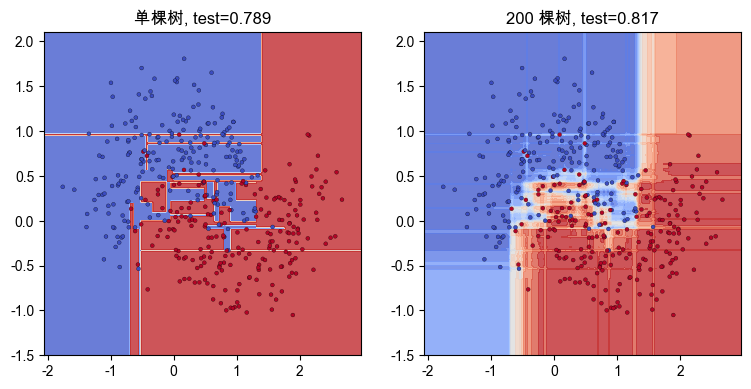

In [6]:
rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_train, y_train)
tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)

xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 300),
                     np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))

for ax, model, title in zip(axs, [tree, rf], ["单棵树", "200 棵树"]):
    Z = model.predict_proba(grid)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=15, cmap="coolwarm", alpha=0.8)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=8, cmap="coolwarm",
               edgecolor="black", linewidth=0.2)
    ax.set_title(f"{title}, test={model.score(X_test, y_test):.3f}")

plt.show()

左边是单树的概率:同一个叶子里所有点概率完全一样,所以边界是直来直去的色块,很多地方从深蓝直接跳到深红。右边是 200 棵树平均的,颜色一层层过渡,因为每棵树在那一片画的位置都不太一样。

这就是平均降低方差在图上长什么样:每棵树都乱一点,但乱的方向不同,平均之后互相抵消,概率就变连续了。

## 6. OOB 分数

每棵树抽样时大概有 36.8% 的样本没被抽到((1 - 1/n)^n 在 n 大时趋近 1/e)。对这些样本来说,这棵树没见过它们,可以拿来当验证集。

每个样本都只用没见过它的那些树来预测,算出来的准确率就是 OOB 分数。相当于免费得到一份验证集。

In [7]:
rf_oob = RandomForestClassifier(n_estimators=200, random_state=0, oob_score=True).fit(X_train, y_train)

print("OOB:", round(rf_oob.oob_score_, 4))
print("CV :", round(rf_cv, 4))
print("测试集:", round(rf_oob.score(X_test, y_test), 4))

OOB: 0.8595
CV : 0.8717
测试集: 0.8167


OOB 0.8595,CV 0.872,测试集 0.8167。OOB 和 CV 都是对泛化能力的估计,差 0.012 属于正常波动;测试集那 180 个样本更少,波动更大。

OOB 不用重新切数据也不用重训,数据少的时候挺好用。

## 7. 特征重要性

换成乳腺癌数据,30 个特征,单树和森林各训一次,看重要性稳不稳。

In [8]:
from sklearn.datasets import load_breast_cancer

Xc, yc = load_breast_cancer(return_X_y=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.3, random_state=0, stratify=yc)

tree_c = DecisionTreeClassifier(random_state=0).fit(Xc_train, yc_train)
rf_c = RandomForestClassifier(n_estimators=300, random_state=0, oob_score=True).fit(Xc_train, yc_train)

print("单树 test:", round(tree_c.score(Xc_test, yc_test), 4))
print("森林 test:", round(rf_c.score(Xc_test, yc_test), 4), "oob:", round(rf_c.oob_score_, 4))

单树 test: 0.9064
森林 test: 0.9532 oob: 0.9673


In [9]:
names = load_breast_cancer().feature_names
order = np.argsort(rf_c.feature_importances_)[::-1][:5]

for i in order:
    print(f"{names[i]:<25} 单树 {tree_c.feature_importances_[i]:.3f}   森林 {rf_c.feature_importances_[i]:.3f}")

worst perimeter           单树 0.800   森林 0.134
worst radius              单树 0.000   森林 0.132
worst concave points      单树 0.042   森林 0.117
mean concave points       单树 0.000   森林 0.108
worst area                单树 0.000   森林 0.107


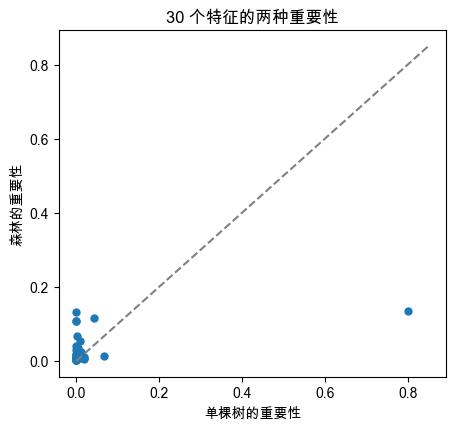

In [10]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(tree_c.feature_importances_, rf_c.feature_importances_, s=25)
ax.plot([0, 0.85], [0, 0.85], color="gray", linestyle="--")
ax.set_xlabel("单棵树的重要性")
ax.set_ylabel("森林的重要性")
ax.set_title("30 个特征的两种重要性")
plt.show()

点大多落在参考线下方,意思是森林把重要性分摊给了更多特征。

单树把 0.8 全压在 worst perimeter 一个特征上,原因是它第一个分裂就把大部分样本分开了,后面几个特征只能捡剩下的。森林里每棵树的根节点都不一样,累计下来就均匀多了。

所以单树的特征重要性只能当参考,森林的靠谱一些,但仍然是训练集上的统计。两个特征高度相关的时候,重要性会在它们之间随机分配,想看清楚用 `permutation_importance` 更稳。

## 8. 小结

- 森林降的是方差,不是偏差。单树能做到训练集 1.0,森林也是 1.0,差别在测试集;
- 两处随机性各有分工:bagging 让每棵树看不同的样本,随机特征让它们看不同的变量;
- 树的数量到 50 到 100 之后就饱和了,再多只是浪费算力;
- OOB 是免费的验证集,和 CV 对得上就可以放心用;
- 特征重要性在森林里更稳,但它衡量的是不纯度下降,特征相关时会互相分摊,别硬解释成因果。